In [ ]:
import numpy as np
from tensorflow import keras
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import os
import zipfile

# Гречишкин Денис, ПМ-41
## Лабораторная работа №2
## Нейронные сети

## Цели работы: работа с предобученными сверточными сетями. Адаптация готовых сетей под новые задачи распознания изображений.

## Часть 1. Перенос обучения и сверточные сети
## 1.1 Подготовка к работе.

In [ ]:
# 1. Скачиваем архив
_URL = 'https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip'
path_to_zip = tf.keras.utils.get_file(
    'cats_and_dogs_filtered.zip',
    origin=_URL,
    extract=False # Ставим False, распакуем сами ниже для надежности
)

# 2. Определяем путь к папке, куда скачался файл
base_dir = os.path.dirname(path_to_zip)

# 3. Ручная распаковка (Гарантирует, что папки появятся)
print(f"Распаковка архива из {path_to_zip}...")
with zipfile.ZipFile(path_to_zip, 'r') as zip_ref:
    zip_ref.extractall(base_dir)
print("Распаковка завершена.")

# 4. Формируем пути
PATH = os.path.join(base_dir, 'cats_and_dogs_filtered')
train_dir = os.path.join(PATH, 'train')
validation_dir = os.path.join(PATH, 'validation')

# Проверка: выведем список папок, чтобы убедиться, что всё на месте
if os.path.exists(train_dir):
    print(f"Папка train найдена: {train_dir}")
else:
    print(f"ОШИБКА: Папка train всё еще не найдена. Содержимое {PATH}:")
    print(os.listdir(PATH))

BATCH_SIZE = 32
IMG_SIZE = (150, 150)

# 5. Загружаем датасеты
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

68606236/68606236 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Распаковка архива из /root/.keras/datasets/cats_and_dogs_filtered.zip...
Распаковка завершена.
Папка train найдена: /root/.keras/datasets/cats_and_dogs_filtered/train
Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


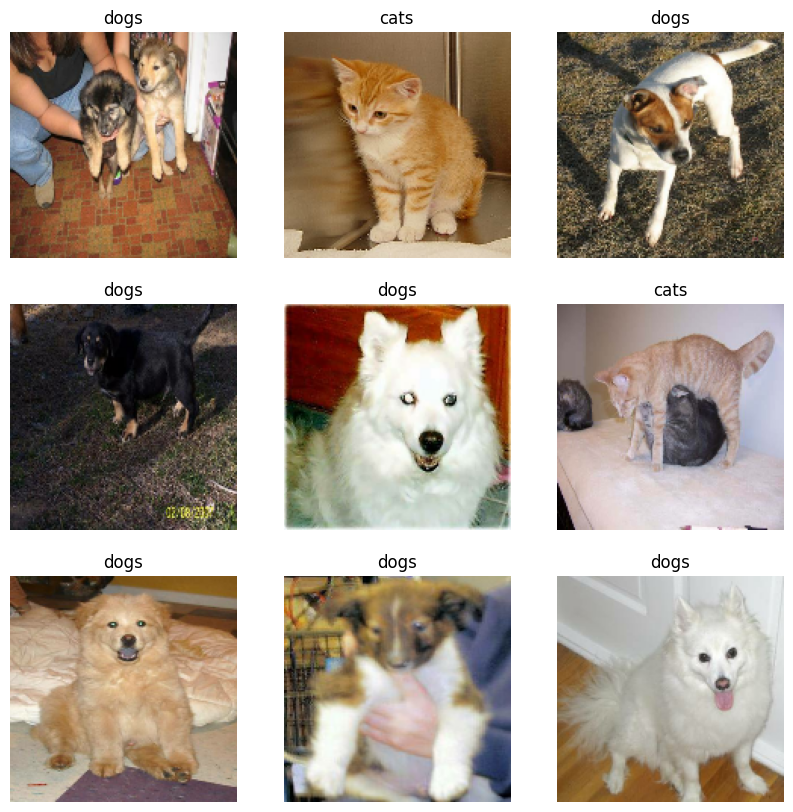

In [ ]:
class_names = train_dataset.class_names
plt.figure(figsize=(10, 10))
for images, labels in train_dataset.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

In [ ]:
val_batches = tf.data.experimental.cardinality(validation_dataset)
test_dataset = validation_dataset.take(val_batches // 5)
validation_dataset = validation_dataset.skip(val_batches // 5)

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

## 1.2. Искуственное расширение обучающей выборки.

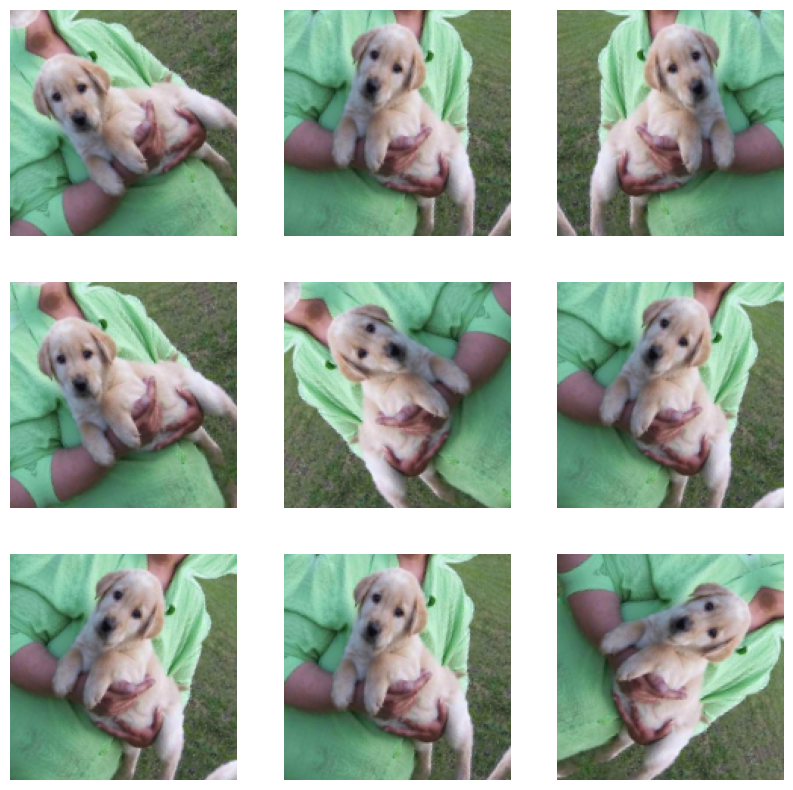

In [ ]:
data_augmentation = tf.keras.Sequential([
 tf.keras.layers.RandomFlip('horizontal'), # симметрическое отражение
 tf.keras.layers.RandomRotation(0.2),
 # поворот изображения
 ])
for image, _ in train_dataset.take(1):
 plt.figure(figsize=(10, 10))
 first_image = image[0]
 for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
  plt.imshow(augmented_image[0] / 255)
  plt.axis('off')

## 1.3. Перенос обучения с готовой модели.

In [ ]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
include_top=False,
weights='imagenet')

/tmp/ipython-input-2812932912.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [ ]:
base_model.trainable = False
base_model.summary() # проверим что они заморозились

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 150, 150,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 75, 75,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 75, 75,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 75, 75,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 75, 75,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 75, 75,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 75, 75,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 77, 77,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 38, 38,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 38, 38,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
inputs = tf.keras.Input(shape=(150, 150, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(1)(x)
model = tf.keras.Model(inputs, outputs)

In [ ]:
base_learning_rate = 0.0001
model.compile(
optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
metrics=['accuracy'])

In [ ]:
initial_epochs = 10
history = model.fit(train_dataset,
epochs=initial_epochs,
validation_data=validation_dataset)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 67s 969ms/step - accuracy: 0.3496 - loss: 1.2598 - val_accuracy: 0.5210 - val_loss: 0.7954
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 74s 835ms/step - accuracy: 0.5593 - loss: 0.8212 - val_accuracy: 0.7092 - val_loss: 0.5155
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 52s 834ms/step - accuracy: 0.6849 - loss: 0.5817 - val_accuracy: 0.8045 - val_loss: 0.3593
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 83s 843ms/step - accuracy: 0.7786 - loss: 0.4377 - val_accuracy: 0.8676 - val_loss: 0.2766
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 83s 864ms/step - accuracy: 0.8007 - loss: 0.3966 - val_accuracy: 0.9022 - val_loss: 0.2173
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 52s 828ms/step - accuracy: 0.8411 - loss: 0.3500 - val_accuracy: 0.9109 - val_loss: 0.1943
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 81s 813ms/step - accuracy: 0.8435 - loss: 0.3126 - val_accuracy: 0.9344 - val_loss: 0.1678
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 84s 849ms/step - accuracy: 0.8711 - loss: 0.2897 - val_accu

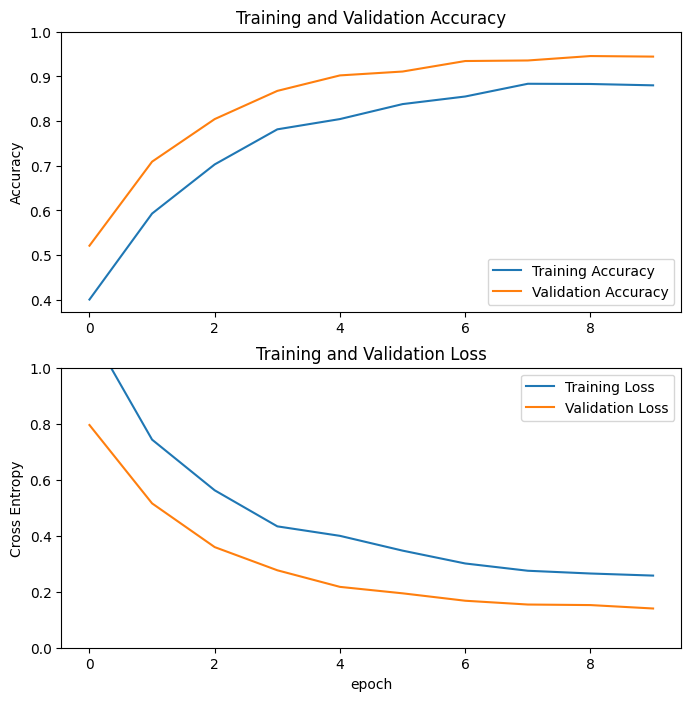

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')
plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

## 1.4. Тонкая настройка модели.

In [ ]:
base_model.trainable = True

new_rate = base_learning_rate/10
model.compile(
loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
optimizer = tf.keras.optimizers.RMSprop(learning_rate=new_rate),
metrics=['accuracy'])
model.summary() # проверяем что слои разморозились

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 2,225,153 (8.49 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [ ]:
fine_tune_epochs = 10
total_epochs = initial_epochs + fine_tune_epochs
history_fine = model.fit(train_dataset,
epochs=total_epochs,
initial_epoch=history.epoch[-1],
validation_data=validation_dataset)

Epoch 10/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 222s 3s/step - accuracy: 0.7913 - loss: 0.4824 - val_accuracy: 0.9666 - val_loss: 0.1019
Epoch 11/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 186s 3s/step - accuracy: 0.8565 - loss: 0.3240 - val_accuracy: 0.9653 - val_loss: 0.0886
Epoch 12/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 202s 3s/step - accuracy: 0.8802 - loss: 0.2756 - val_accuracy: 0.9691 - val_loss: 0.0764
Epoch 13/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 187s 3s/step - accuracy: 0.9080 - loss: 0.2350 - val_accuracy: 0.9752 - val_loss: 0.0673
Epoch 14/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 184s 3s/step - accuracy: 0.9192 - loss: 0.2012 - val_accuracy: 0.9740 - val_loss: 0.0700
Epoch 15/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 186s 3s/step - accuracy: 0.9194 - loss: 0.1977 - val_accuracy: 0.9790 - val_loss: 0.0645
Epoch 16/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 187s 3s/step - accuracy: 0.9221 - loss: 0.1727 - val_accuracy: 0.9765 - val_loss: 0.0644
Epoch 17/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 186s 3s/step - accuracy: 0.9179 - loss: 0.1806 - val_accuracy: 0.

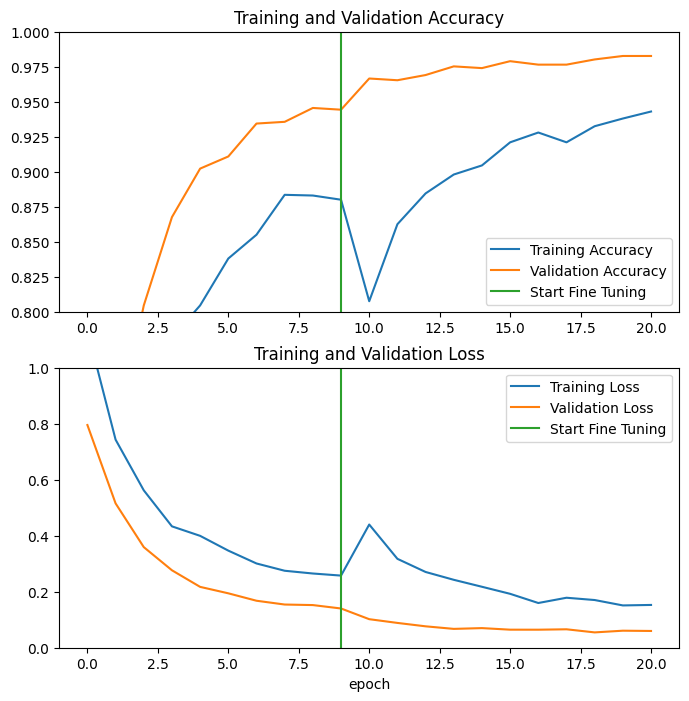

In [ ]:
acc += history_fine.history['accuracy']
val_acc += history_fine.history['val_accuracy']
loss += history_fine.history['loss']
val_loss += history_fine.history['val_loss']
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.ylim([0.8, 1])
plt.plot([initial_epochs-1,initial_epochs-1],
plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.ylim([0, 1.0])
plt.plot([initial_epochs-1,initial_epochs-1],
plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

In [ ]:
loss, accuracy = model.evaluate(test_dataset)
print('Test accuracy :', accuracy)
print('Test loss:', loss)

6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 688ms/step - accuracy: 0.9769 - loss: 0.0701
Test accuracy : 0.96875


In [ ]:
model.save('our_first_convmodel.h5')

## часть 2: Построение автоэнкодера на основе сверточных сетей

In [ ]:
from __future__ import absolute_import
from __future__ import division
import keras
from keras.datasets import mnist
import numpy as np
# Считываем данные из MNIST
(x_train, _), (x_test, _) = mnist.load_data()
# Нормируем данные и приводим массивы к виду (N,size1,size1,1)
image_size = x_train.shape[1]
x_train = np.reshape(x_train, [-1, image_size, image_size, 1])
x_test = np.reshape(x_test, [-1, image_size, image_size, 1])
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
noise = np.random.normal(loc=0.5, scale=0.5, size=x_train.shape)
x_train_noisy = x_train + noise
noise = np.random.normal(loc=0.5, scale=0.5, size=x_test.shape)
x_test_noisy = x_test + noise
# Ограничим итоговые значения интервалом [0,1]
x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)
input_shape = (image_size, image_size, 1)
batch_size = 128
kernel_size = 3
latent_dim = 16
# Зададим два сверточных слоя и число нейронов в каждом слое:
layer_filters = [32, 64]

In [ ]:
from tensorflow.keras.layers import Activation, Dense, Input
from tensorflow.keras.layers import Conv2D, Flatten
from tensorflow.keras.layers import Reshape, Conv2DTranspose
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K

In [ ]:
encoder_inputs = Input(shape=input_shape, name='encoder_input')
x = encoder_inputs
# Стек из сверточных слоев (strides- дискрет сдвига окна свертки
# в пикселях, padding- без заполнения нулями):
for filters in layer_filters:
  x = Conv2D(filters=filters,
  kernel_size=kernel_size,
  strides=2,
  activation='relu',
  padding='same')(x)
# Запоминаем размерность выхода для построения модели декодера
shape = K.int_shape(x)
# Преобразуем многомерный массив в вектор
x = Flatten()(x)
latent = Dense(latent_dim, name='latent_vector')(x)
# Итоговый код- одномерный вектор меньшей размерности (latent_dim)
# Итоговая модель энкодера:
encoder = Model(encoder_inputs , latent, name='encoder')
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 14, 14, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 16)             │        50,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,008 (269.56 KB)

 Trainable params: 69,008 (269.56 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
 latent_inputs = Input(shape=(latent_dim,), name='decoder_input')
 # Обратное преобразование к размеру "shape":
 x = Dense(shape[1] * shape[2] * shape[3])(latent_inputs)
 # Выход должен быть трехмерным массивом:
 x = Reshape((shape[1], shape[2], shape[3]))(x)
 # Вместо сверточных слоев "разверточные", цикл в обратном порядке:
 for filters in layer_filters[::-1]:
  x = Conv2DTranspose(filters=filters,
  kernel_size=kernel_size,
  strides=2,
  activation='relu',
  padding='same')(x)
 x = Conv2DTranspose(filters=1,
 kernel_size=kernel_size,
 padding='same')(x)
 outputs = Activation('sigmoid', name='decoder_output')(x)
 # Итоговая модель декодера:
 decoder = Model(latent_inputs, outputs, name='decoder')
 decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3136)           │        53,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Activation)     │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,993 (425.75 KB)

 Trainable params: 108,993 (425.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
autoencoder = Model(encoder_inputs,
 decoder(encoder(encoder_inputs)),
 name='autoencoder')
autoencoder.compile(loss='mse', optimizer='adam')
# Запускаем модель на обучение, используя незашумленные данные как эталонные.
autoencoder.fit(x_train_noisy,
x_train,
validation_data=(x_test_noisy, x_test),
epochs=30,
batch_size=batch_size)

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 92s 190ms/step - loss: 0.0847 - val_loss: 0.0308
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 89s 190ms/step - loss: 0.0277 - val_loss: 0.0218
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 87s 186ms/step - loss: 0.0216 - val_loss: 0.0196
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 140s 181ms/step - loss: 0.0194 - val_loss: 0.0184
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 81s 174ms/step - loss: 0.0183 - val_loss: 0.0180
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 174ms/step - loss: 0.0176 - val_loss: 0.0173
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 175ms/step - loss: 0.0170 - val_loss: 0.0169
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 82s 176ms/step - loss: 0.0166 - val_loss: 0.0168
Epoch 9/30
  4/469 ━━━━━━━━━━━━━━━━━━━━ 2:05 269ms/step - loss: 0.0172

# практические задания

## Задание № 1: Классификация изображений.
1. Выбрать один из стандартных датасетов для классификации изображений (совпадение датасетов допускается у 2-3 студентов).
2. Загрузить данные, разбив изображения на обучающую и тестовую выборки. Предусмотреть аугментацию данных.
3. Импортировать сверточную сеть и адаптировать для обработки и распознания классов изображений из выбранного датасета.
4. Обучить сеть с заморозкой предобученных слоев, а затем разморозить их и повторить обучение с меньшим числом эпох.
5. Сравнить качество и скорость обучения при использовании заморозки коэффициентов предобученных слоев и без заморозки.

## Решение
### пункты 1 и 2

In [ ]:
BATCH_SIZE = 32
IMG_SIZE = (32, 32)
dataset_name = 'cifar10'
dataset, info = tfds.load(
    dataset_name,
    split=['train', 'test'],
    with_info=True,
    as_supervised=True
)

print(f"Имена классов: {info.features['label'].names}")

# 3. Функция предобработки
def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# 4. Создаем train/validation сплиты
if len(dataset) == 2:
    train_dataset, test_dataset = dataset
    train_size = info.splits['train'].num_examples
    val_split = 0.2
    val_size = int(train_size * val_split)

    train_dataset = train_dataset.skip(val_size)
    validation_dataset = train_dataset.take(val_size)
else:
    train_dataset = dataset['train']
    validation_dataset = dataset['validation']  # или 'test'

train_dataset = train_dataset.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
validation_dataset = validation_dataset.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Имена классов: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


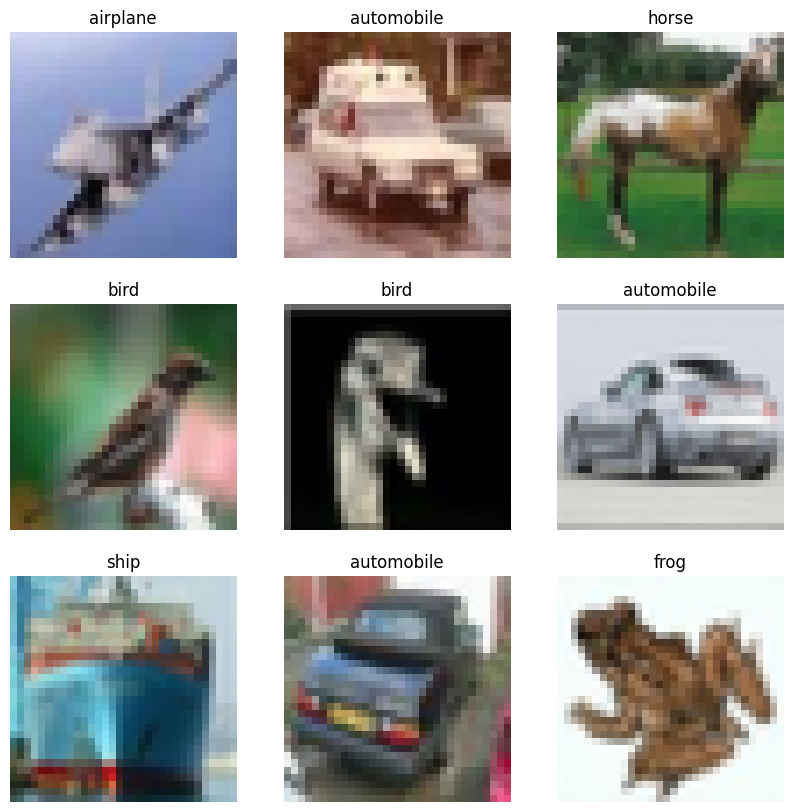

In [ ]:
class_names = info.features['label'].names
plt.figure(figsize=(10, 10))
for images, labels in train_dataset.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(((images[i].numpy())*255).astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

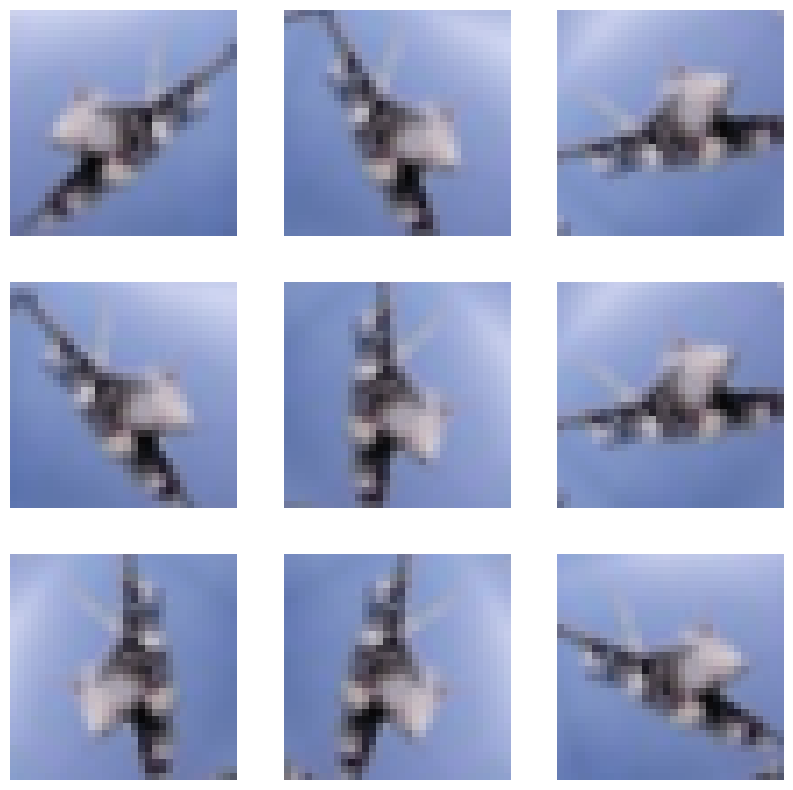

In [ ]:
data_augmentation = tf.keras.Sequential([
 tf.keras.layers.RandomFlip('horizontal'), # симметрическое отражение
 tf.keras.layers.RandomRotation(0.2),
 # поворот изображения
 ])
for image, _ in train_dataset.take(1):
 plt.figure(figsize=(10, 10))
 first_image = image[0]
 for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
  plt.imshow(augmented_image[0])
  plt.axis('off')

### пункт 3

In [ ]:
IMG_SHAPE = (32, 32, 3)
base_model = tf.keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3),
include_top=False,
weights='imagenet')

/tmp/ipython-input-4849/834790297.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3),


In [ ]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

In [ ]:
base_model.trainable = False
base_model.summary() # проверим что они заморозились

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 16, 16,    │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 16, 16,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 16, 16,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 16, 16,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 16, 16,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 16, 16,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 16, 16,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 16, 16,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 16, 16,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 16, 16,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 16, 16,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 17, 17,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 8, 8, 96)  │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 8, 8, 96)  │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 8, 8, 96)  │          0 │ block_1_depthwis… │
│ (ReLU)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 8, 8, 24)  │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
inputs = tf.keras.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
num_classes = info.features['label'].num_classes
outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

### пункт 4

In [ ]:
base_learning_rate = 1e-3
model.compile(
  optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
  metrics=['accuracy'])
initial_epochs = 20
history = model.fit(train_dataset,
  epochs=initial_epochs,
  validation_data=validation_dataset)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 20ms/step - accuracy: 0.1089 - loss: 2.3030 - val_accuracy: 0.1776 - val_loss: 2.2756
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.1367 - loss: 2.2808 - val_accuracy: 0.1957 - val_loss: 2.2564
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.1471 - loss: 2.2697 - val_accuracy: 0.1932 - val_loss: 2.2424
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 25s 19ms/step - accuracy: 0.1533 - loss: 2.2612 - val_accuracy: 0.2000 - val_loss: 2.2320
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.1537 - loss: 2.2589 - val_accuracy: 0.1984 - val_loss: 2.2252
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.1550 - loss: 2.2529 - val_accuracy: 0.2010 - val_loss: 2.2188
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.1529 - loss: 2.2512 - val_accuracy: 0.2033 - val_loss: 2.2138
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 15ms/step - accuracy: 0.1570 -

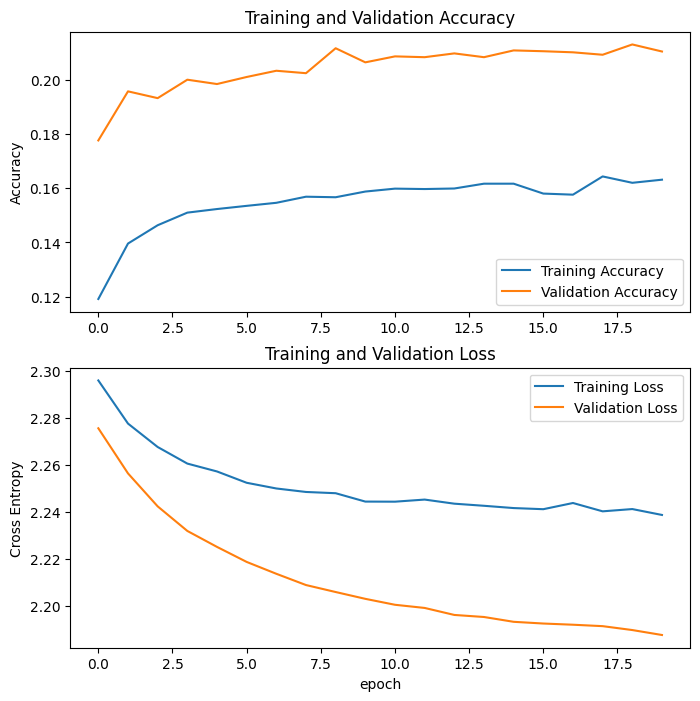

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.axis()

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation Loss')
plt.axis()
plt.xlabel('epoch')
plt.show()

In [ ]:
base_model.trainable = True

new_rate = base_learning_rate/10
model.compile(
  optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
  loss=tf.keras.losses.SparseCategoricalCrossentropy(),
  metrics=['accuracy'])
model.summary() # проверяем что слои разморозились

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1, 1, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 2,236,682 (8.53 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [ ]:
fine_tune_epochs = 5
total_epochs = initial_epochs + fine_tune_epochs
history_fine = model.fit(train_dataset,
epochs=total_epochs,
initial_epoch=history.epoch[-1],
validation_data=validation_dataset)

Epoch 20/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 133s 81ms/step - accuracy: 0.1159 - loss: 3.0004 - val_accuracy: 0.0946 - val_loss: 6.0759
Epoch 21/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 97s 77ms/step - accuracy: 0.1221 - loss: 2.5057 - val_accuracy: 0.1021 - val_loss: 7.1478
Epoch 22/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 95s 76ms/step - accuracy: 0.1245 - loss: 2.5457 - val_accuracy: 0.0997 - val_loss: 2.3256
Epoch 23/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 93s 75ms/step - accuracy: 0.1101 - loss: 2.5309 - val_accuracy: 0.0958 - val_loss: 5.2115
Epoch 24/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 95s 76ms/step - accuracy: 0.1133 - loss: 2.4641 - val_accuracy: 0.0946 - val_loss: 4.8403
Epoch 25/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 93s 74ms/step - accuracy: 0.1106 - loss: 2.4730 - val_accuracy: 0.0997 - val_loss: 5.6543


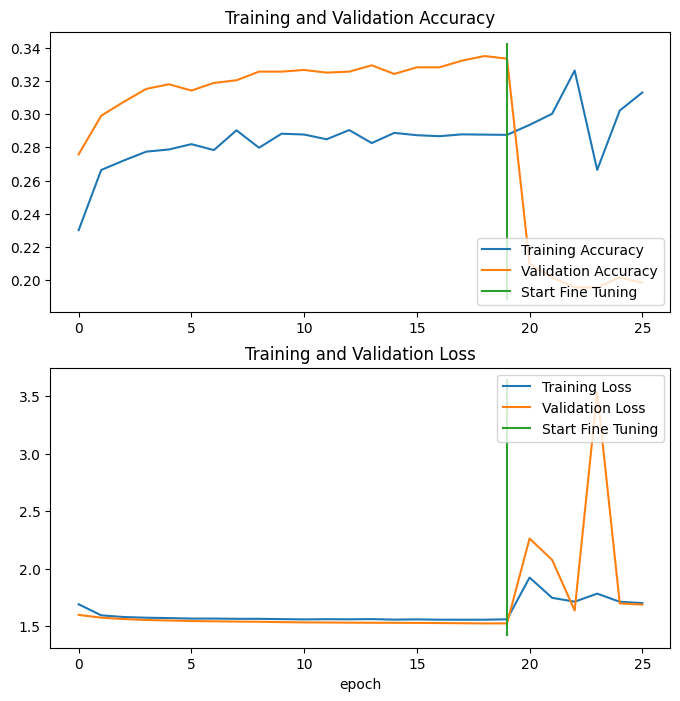

In [ ]:
acc += history_fine.history['accuracy']
val_acc += history_fine.history['val_accuracy']
loss += history_fine.history['loss']
val_loss += history_fine.history['val_loss']
plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.plot([initial_epochs-1,initial_epochs-1],
plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.plot([initial_epochs-1,initial_epochs-1],
plt.ylim(), label='Start Fine Tuning')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

## Задание № 2: Автоэнкодеры.
1. Доработать модель из разобранного примера, предусмотрев визуализацию итогового результата.
2. Вывести в виде изображений зашумленные и исправленные данные.
3. Реализовать альтернативную модель автоэнкодера с тремя слоями сверт
ки/развертки. Сравнить качество работы с моделью из примера.

### пункт 1

In [ ]:
from __future__ import absolute_import
from __future__ import division
import keras
from keras.datasets import mnist
import numpy as np
# Считываем данные из MNIST
(x_train, _), (x_test, _) = mnist.load_data()
# Нормируем данные и приводим массивы к виду (N,size1,size1,1)
image_size = x_train.shape[1]
x_train = np.reshape(x_train, [-1, image_size, image_size, 1])
x_test = np.reshape(x_test, [-1, image_size, image_size, 1])
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
noise = np.random.normal(loc=0.5, scale=0.5, size=x_train.shape)
x_train_noisy = x_train + noise
noise = np.random.normal(loc=0.5, scale=0.5, size=x_test.shape)
x_test_noisy = x_test + noise
# Ограничим итоговые значения интервалом [0,1]
x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)
input_shape = (image_size, image_size, 1)
batch_size = 128
kernel_size = 3
latent_dim = 16
# Зададим два сверточных слоя и число нейронов в каждом слое:
layer_filters = [32, 64]

In [ ]:
from tensorflow.keras.layers import Activation, Dense, Input
from tensorflow.keras.layers import Conv2D, Flatten
from tensorflow.keras.layers import Reshape, Conv2DTranspose
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K

encoder_inputs = Input(shape=input_shape, name='encoder_input')
x = encoder_inputs
# Стек из сверточных слоев (strides- дискрет сдвига окна свертки
# в пикселях, padding- без заполнения нулями):
for filters in layer_filters:
  x = Conv2D(filters=filters,
  kernel_size=kernel_size,
  strides=2,
  activation='relu',
  padding='same')(x)
# Запоминаем размерность выхода для построения модели декодера
shape = K.int_shape(x)
# Преобразуем многомерный массив в вектор
x = Flatten()(x)
latent = Dense(latent_dim, name='latent_vector')(x)
# Итоговый код- одномерный вектор меньшей размерности (latent_dim)
# Итоговая модель энкодера:
encoder = Model(encoder_inputs , latent, name='encoder')
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 14, 14, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 16)             │        50,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,008 (269.56 KB)

 Trainable params: 69,008 (269.56 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
latent_inputs = Input(shape=(latent_dim,), name='decoder_input')
# Обратное преобразование к размеру "shape":
x = Dense(shape[1] * shape[2] * shape[3])(latent_inputs)
# Выход должен быть трехмерным массивом:
x = Reshape((shape[1], shape[2], shape[3]))(x)
# Вместо сверточных слоев "разверточные", цикл в обратном порядке:
for filters in layer_filters[::-1]:
  x = Conv2DTranspose(filters=filters,
  kernel_size=kernel_size,
  strides=2,
  activation='relu',
  padding='same')(x)
x = Conv2DTranspose(filters=1,
  kernel_size=kernel_size,
  padding='same')(x)
outputs = Activation('sigmoid', name='decoder_output')(x)
# Итоговая модель декодера:
decoder = Model(latent_inputs, outputs, name='decoder')
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3136)           │        53,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Activation)     │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,993 (425.75 KB)

 Trainable params: 108,993 (425.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
autoencoder = Model(encoder_inputs,
 decoder(encoder(encoder_inputs)),
 name='autoencoder')
autoencoder.compile(loss='mse', optimizer='adam')
# Запускаем модель на обучение, используя незашумленные данные как эталонные.
history = autoencoder.fit(x_train_noisy,
  x_train,
  validation_data=(x_test_noisy, x_test),
  epochs=30,
  batch_size=batch_size)

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 0.0865 - val_loss: 0.0360
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0313 - val_loss: 0.0232
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0225 - val_loss: 0.0200
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0199 - val_loss: 0.0188
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0186 - val_loss: 0.0181
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0179 - val_loss: 0.0176
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0173 - val_loss: 0.0173
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0169 - val_loss: 0.0170
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0166 - val_loss: 0.0169
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0164 - val_loss: 0.0168
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0161 - val_loss: 0.0166
Epoch 12/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/st

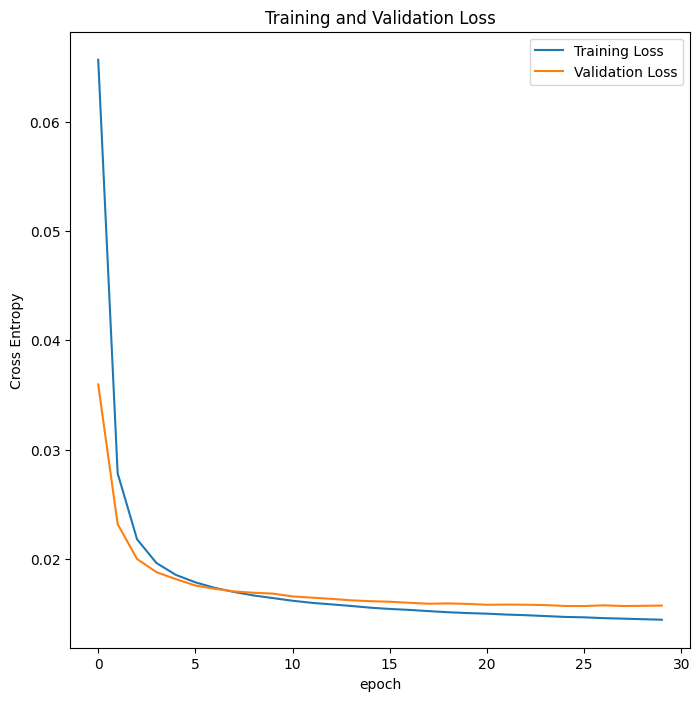

In [ ]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation Loss')
plt.axis()
plt.xlabel('epoch')
plt.show()

### пункт 2

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


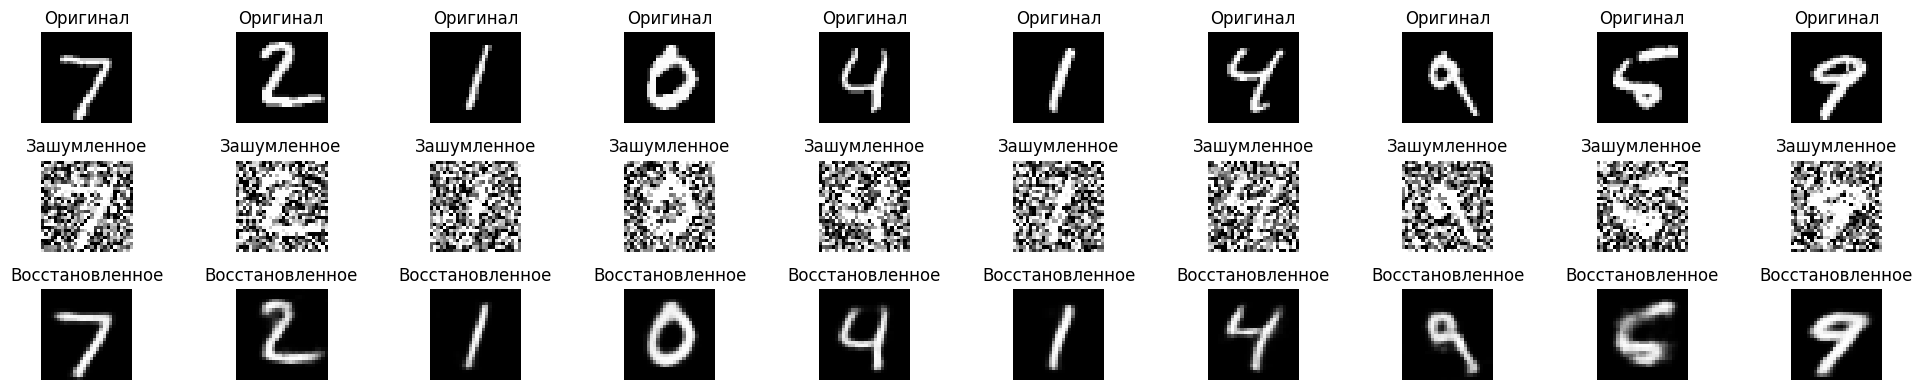

In [ ]:
import matplotlib.pyplot as plt
decoded_imgs = autoencoder.predict(x_test_noisy)

n = 10
plt.figure(figsize=(20, 4))

for i in range(n):
    # Оригинал
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(image_size, image_size), cmap='gray')
    plt.title("Оригинал")
    plt.axis('off')

    # Зашумленное
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].reshape(image_size, image_size), cmap='gray')
    plt.title("Зашумленное")
    plt.axis('off')

    # Восстановленное
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i].reshape(image_size, image_size), cmap='gray')
    plt.title("Восстановленное")
    plt.axis('off')

plt.tight_layout()
plt.show()

### пункт 3

In [ ]:
from __future__ import absolute_import
from __future__ import division
import keras
from keras.datasets import mnist
import numpy as np
# Считываем данные из MNIST
(x_train, _), (x_test, _) = mnist.load_data()
# Нормируем данные и приводим массивы к виду (N,size1,size1,1)
image_size = x_train.shape[1]
x_train = np.reshape(x_train, [-1, image_size, image_size, 1])
x_test = np.reshape(x_test, [-1, image_size, image_size, 1])
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

In [ ]:
noise = np.random.normal(loc=0.5, scale=0.5, size=x_train.shape)
x_train_noisy = x_train + noise
noise = np.random.normal(loc=0.5, scale=0.5, size=x_test.shape)
x_test_noisy = x_test + noise
# Ограничим итоговые значения интервалом [0,1]
x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)
input_shape = (image_size, image_size, 1)
batch_size = 128
kernel_size = 3
latent_dim = 16
# Зададим 3 сверточных слоя и число нейронов в каждом слое:
layer_filters = [32, 64, 64]

In [ ]:
from tensorflow.keras.layers import Activation, Dense, Input
from tensorflow.keras.layers import Conv2D, Flatten
from tensorflow.keras.layers import Reshape, Conv2DTranspose
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K

encoder_inputs = Input(shape=input_shape, name='encoder_input')
x = encoder_inputs
x = Conv2D(filters=layer_filters[0],
  kernel_size=kernel_size,
  strides=2,
  activation='relu',
  padding='same')(x)

x = Conv2D(filters=layer_filters[1],
  kernel_size=kernel_size,
  strides=2,
  activation='relu',
  padding='same')(x)

x = Conv2D(filters=layer_filters[2],
  kernel_size=kernel_size,
  strides=1,
  activation='relu',
  padding='same')(x)

shape = K.int_shape(x)
x = Flatten()(x)
latent = Dense(latent_dim, name='latent_vector')(x)
encoder = Model(encoder_inputs , latent, name='encoder')
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 16)             │        50,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,936 (413.81 KB)

 Trainable params: 105,936 (413.81 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
latent_inputs = Input(shape=(latent_dim,), name='decoder_input')

# Обратное преобразование к размеру "shape" (7x7)
x = Dense(shape[1] * shape[2] * shape[3])(latent_inputs)
x = Reshape((shape[1], shape[2], shape[3]))(x)

x = Conv2DTranspose(filters=layer_filters[1],
                    kernel_size=kernel_size,
                    strides=2,
                    activation='relu',
                    padding='same')(x)

x = Conv2DTranspose(filters=layer_filters[0],
                    kernel_size=kernel_size,
                    strides=2,
                    activation='relu',
                    padding='same')(x)

x = Conv2DTranspose(filters=1,
                    kernel_size=kernel_size,
                    strides=1,
                    padding='same')(x)

outputs = Activation('sigmoid', name='decoder_output')(x)
# Итоговая модель декодера:
decoder = Model(latent_inputs, outputs, name='decoder')
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3136)           │        53,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Activation)     │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,993 (425.75 KB)

 Trainable params: 108,993 (425.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
autoencoder = Model(encoder_inputs,
 decoder(encoder(encoder_inputs)),
 name='autoencoder')
autoencoder.compile(loss='mse', optimizer='adam')
# Запускаем модель на обучение, используя незашумленные данные как эталонные.
history = autoencoder.fit(x_train_noisy,
  x_train,
  validation_data=(x_test_noisy, x_test),
  epochs=30,
  batch_size=batch_size)

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.0850 - val_loss: 0.0336
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0280 - val_loss: 0.0210
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0205 - val_loss: 0.0184
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0184 - val_loss: 0.0173
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0172 - val_loss: 0.0167
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0165 - val_loss: 0.0163
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0160 - val_loss: 0.0161
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0155 - val_loss: 0.0157
Epoch 9/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0152 - val_loss: 0.0156
Epoch 10/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0148 - val_loss: 0.0153
Epoch 11/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0147 - val_loss: 0.0151
Epoch 12/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/st

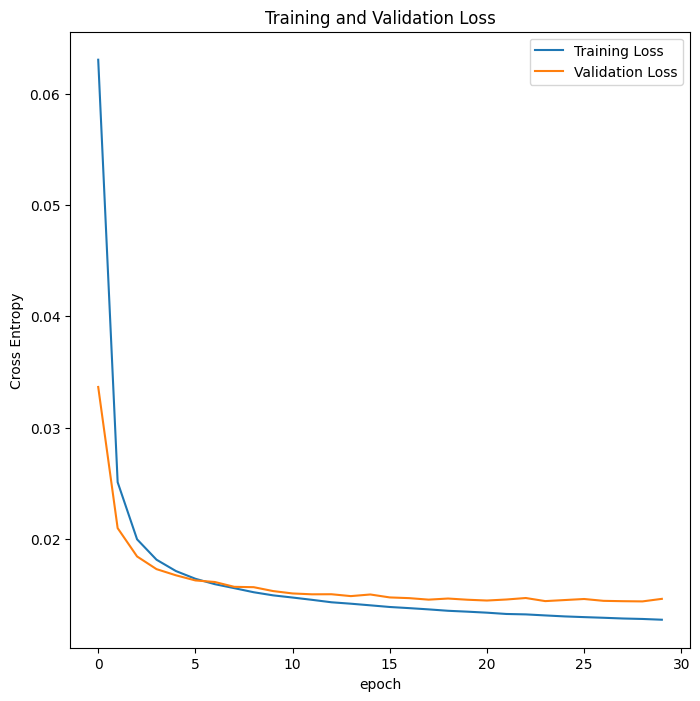

In [ ]:
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation Loss')
plt.axis()
plt.xlabel('epoch')
plt.show()

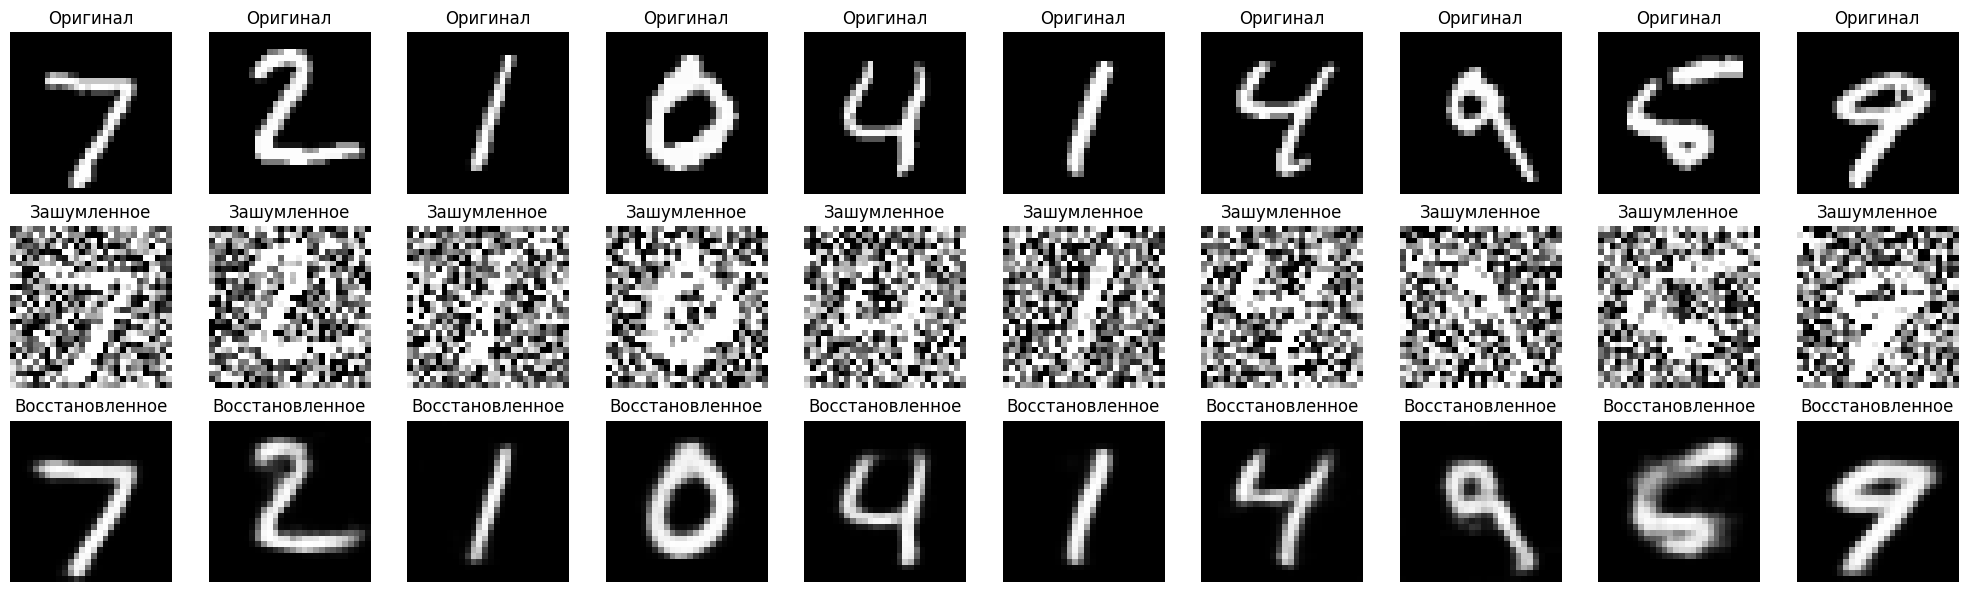

In [ ]:
n = 10
plt.figure(figsize=(20, 6))
for i in range(n):
    # Оригинал
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].reshape(image_size, image_size), cmap='gray')
    plt.title("Оригинал")
    plt.axis('off')

    # Зашумленное
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test_noisy[i].reshape(image_size, image_size), cmap='gray')
    plt.title("Зашумленное")
    plt.axis('off')

    # Восстановленное
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_imgs[i].reshape(image_size, image_size), cmap='gray')
    plt.title("Восстановленное")
    plt.axis('off')

plt.tight_layout()
plt.show()